# Análise do dataset UFPR

Objetivo: conhecer os dados antes de decidir como treinar o detector e avaliar o OCR.
Esta auditoria lê os arquivos brutos, preserva as divisões oficiais e não inicia treinamento.
Tudo fica neste notebook: funções, resultados, gráficos e conclusões. Nenhuma pasta de resultados é criada.
Execute as células em ordem; a leitura integral das imagens pode demorar alguns minutos.


### 1. Como localizar o projeto e preparar as ferramentas?

Procuramos `datasets_brutos` no diretório atual e em seus pais; assim, funciona tanto
na raiz quanto em `src`. Usamos as bibliotecas já presentes no ambiente do projeto,
sem executar instalação de pacotes ao abrir o notebook.


### Funções usadas na análise

Estas células definem as operações da auditoria. Não leem nem alteram os datasets até serem chamadas.


In [1]:
# Ferramentas da auditoria; resultados permanecem em memória e nas saídas do notebook.
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import csv
import hashlib
import json
import re
import cv2
import numpy as np
from PIL import Image
DIVISOES = ('training', 'validation', 'testing')
PASTAS = {'UFPR': 'UFPR-ALPR dataset', 'RodoSol': 'tbFcZE-RodoSol-ALPR'}


In [2]:
def localizar_raiz(inicio=None):
    inicio = Path(inicio or Path.cwd()).resolve()
    for pasta in (inicio, *inicio.parents):
        if (pasta / 'datasets_brutos').is_dir():
            return pasta
    raise FileNotFoundError('Execute a partir da raiz do projeto ou de src.')


In [3]:
def ler_anotacao(caminho):
    """Não ignora silenciosamente linhas inválidas nem chaves repetidas."""
    campos = {}
    for numero, linha in enumerate(caminho.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not linha.strip():
            continue
        chave, separador, valor = linha.partition(':')
        chave, valor = (chave.strip(), valor.strip())
        if not separador or not chave or chave in campos:
            raise ValueError(f'Linha {numero}: campo inválido ou repetido')
        campos[chave] = valor
    for chave in ('plate', 'type', 'corners'):
        if not campos.get(chave):
            raise ValueError(f'Campo obrigatório ausente/vazio: {chave}')
    pontos = np.array([[float(n) for n in par.split(',')] for par in campos['corners'].split()], dtype=float)
    if pontos.shape != (4, 2) or not np.isfinite(pontos).all():
        raise ValueError('Esperados quatro pares x,y finitos')
    return (campos, pontos)


In [4]:
def caixa_yolo(pontos, largura, altura):
    minimo, maximo = (pontos.min(axis=0), pontos.max(axis=0))
    centro = (minimo + maximo) / 2
    tamanho = maximo - minimo
    return np.array([centro[0] / largura, centro[1] / altura, tamanho[0] / largura, tamanho[1] / altura])


In [5]:
def inventariar(raiz, nome):
    base = raiz / 'datasets_brutos' / PASTAS[nome]
    extensao = '.png' if nome == 'UFPR' else '.jpg'
    pastas = [base / d for d in DIVISOES] if nome == 'UFPR' else [base / 'images']
    imagens = sorted((p for pasta in pastas for p in pasta.rglob('*') if p.is_file() and p.suffix.lower() == extensao))
    anotacoes = sorted((p for pasta in pastas for p in pasta.rglob('*.txt')))
    ids_imagem = {p.relative_to(base).with_suffix('').as_posix() for p in imagens}
    ids_anotacao = {p.relative_to(base).with_suffix('').as_posix() for p in anotacoes}
    problemas = []
    mapa = {}
    if nome == 'RodoSol':
        for numero, linha in enumerate((base / 'split.txt').read_text(encoding='utf-8-sig').splitlines(), 1):
            if not linha.strip():
                continue
            partes = linha.strip().split(';')
            if len(partes) != 2:
                problemas.append(f'split.txt linha {numero}: formato inválido')
                continue
            caminho, divisao = partes
            relativo = Path(caminho).as_posix().removeprefix('./')
            if relativo in mapa:
                problemas.append(f'split.txt: caminho repetido {relativo}')
            if divisao not in DIVISOES:
                problemas.append(f'split.txt: divisão inválida {divisao}')
            mapa[relativo] = divisao
        reais = {p.relative_to(base).as_posix() for p in imagens}
        problemas += [f'Imagem fora do manifesto: {p}' for p in sorted(reais - mapa.keys())]
        problemas += [f'Manifesto sem imagem: {p}' for p in sorted(mapa.keys() - reais)]
    tarefas = []
    for p in imagens:
        relativo = p.relative_to(base)
        divisao = relativo.parts[0] if nome == 'UFPR' else mapa.get(relativo.as_posix(), 'ausente')
        grupo = relativo.parts[1]
        tarefas.append((p, base, nome, divisao, grupo))
    inventario = dict(dataset=nome, imagens=len(imagens), anotacoes=len(anotacoes), sem_anotacao=sorted(ids_imagem - ids_anotacao), sem_imagem=sorted(ids_anotacao - ids_imagem), problemas_manifesto=problemas)
    return (base, tarefas, inventario)


In [6]:
def analisar_imagem(tarefa):
    caminho, base, nome, divisao, grupo = tarefa
    r = dict(dataset=nome, caminho=caminho.relative_to(base).as_posix(), divisao=divisao, grupo=grupo, erros=[], avisos=[])
    try:
        campos, pontos = ler_anotacao(caminho.with_suffix('.txt'))
        placa = campos['plate'].strip().upper()
        r.update(placa_original=campos['plate'], placa=placa, tipo=campos['type'], layout=campos.get('layout', 'não informado'), camera=campos.get('camera', 'não informado'), cantos=pontos.tolist(), campos=campos)
        if not re.fullmatch('[A-Z]{3}(?:[0-9]{4}|[0-9][A-Z][0-9]{2})', placa):
            r['avisos'].append('texto fora dos padrões brasileiros esperados; revisar, não corrigir automaticamente')
        if nome == 'RodoSol':
            tipo_esperado = 'car' if grupo.startswith('cars-') else 'motorcycle'
            layout_esperado = 'Brazilian' if grupo.endswith('-br') else 'Mercosur'
            if campos['type'] != tipo_esperado or campos.get('layout') != layout_esperado:
                r['erros'].append('grupo diverge de type/layout')
            padrao = '[A-Z]{3}[0-9]{4}' if layout_esperado == 'Brazilian' else '[A-Z]{3}[0-9][A-Z][0-9]{2}'
            if not re.fullmatch(padrao, placa):
                r['avisos'].append('formato do texto diverge do layout')
    except Exception as exc:
        r['erros'].append(f'anotação: {exc}')
        pontos = None
    try:
        r['sha256_arquivo'] = hashlib.sha256(caminho.read_bytes()).hexdigest()
        with Image.open(caminho) as original:
            original.load()
            r['modo_original'] = original.mode
            imagem = original.convert('RGB')
        largura, altura = imagem.size
        r.update(largura=largura, altura=altura)
        r['sha256_pixels'] = hashlib.sha256(f'{largura},{altura},RGB'.encode() + imagem.tobytes()).hexdigest()
        miniatura = imagem.resize((9, 8)).convert('L')
        mini = np.asarray(miniatura)
        bits = mini[:, 1:] > mini[:, :-1]
        r['dhash'] = np.packbits(bits).tobytes().hex()
        if pontos is not None:
            minimo, maximo = (pontos.min(axis=0), pontos.max(axis=0))
            if (minimo < 0).any() or (maximo > [largura, altura]).any():
                r['erros'].append('cantos fora dos limites da imagem')
            contorno = pontos.astype(np.float32)
            area = abs(cv2.contourArea(contorno))
            if area <= 0 or not cv2.isContourConvex(contorno):
                r['erros'].append('quadrilátero degenerado, não convexo ou cruzado')
            w, h = maximo - minimo
            if w <= 0 or h <= 0:
                r['erros'].append('caixa sem área positiva')
            else:
                r.update(largura_placa=float(w), altura_placa=float(h), proporcao=float(w / h), fracao_area=float(w * h / (largura * altura)), ocupacao_poligono=float(area / (w * h)), yolo=caixa_yolo(pontos, largura, altura).tolist(), altura_em_640=float(h * min(640 / largura, 640 / altura)))
                box = (max(0, int(np.floor(minimo[0]))), max(0, int(np.floor(minimo[1]))), min(largura, int(np.ceil(maximo[0]))), min(altura, int(np.ceil(maximo[1]))))
                if box[2] > box[0] and box[3] > box[1]:
                    cinza = np.asarray(imagem.crop(box).convert('L'))
                    r.update(brilho=float(cinza.mean()), contraste=float(cinza.std()), variancia_laplaciano=float(cv2.Laplacian(cinza, cv2.CV_64F).var()))
            if nome == 'UFPR':
                caracteres = [campos[k] for k in campos if re.fullmatch('char \\d+', k)]
                if len(caracteres) != len(placa):
                    r['erros'].append('quantidade de caixas de caracteres diferente do texto')
                for valor in caracteres:
                    valores = [float(v) for v in valor.split()]
                    if len(valores) != 4 or not np.isfinite(valores).all():
                        r['erros'].append('caixa de caractere inválida')
                        continue
                    x, y, cw, ch = valores
                    if min(x, y) < 0 or min(cw, ch) <= 0 or x + cw > largura or (y + ch > altura):
                        r['erros'].append('caixa de caractere fora da imagem ou sem área')
    except Exception as exc:
        r['erros'].append(f'imagem/métricas: {exc}')
    r['apto_geometria_yolo'] = not r['erros'] and 'yolo' in r
    return r


In [7]:
def grupos_repetidos(registros, campo):
    grupos = defaultdict(list)
    for r in registros:
        if r.get(campo):
            grupos[r[campo]].append({'dataset': r['dataset'], 'caminho': r['caminho'], 'divisao': r['divisao']})
    return {k: v for k, v in grupos.items() if len(v) > 1}


In [8]:
def estatisticas(registros, campo):
    valores = [r[campo] for r in registros if campo in r]
    if not valores:
        return {}
    return dict(zip(('min', 'p05', 'mediana', 'p95', 'max'), map(float, np.percentile(valores, [0, 5, 50, 95, 100]))))


In [9]:
def resumir(registros):
    resumo = {'total': len(registros), 'com_erros': sum((bool(r['erros']) for r in registros)), 'com_avisos': sum((bool(r['avisos']) for r in registros)), 'aptos_geometria_yolo': sum((r['apto_geometria_yolo'] for r in registros))}
    for campo in ('divisao', 'tipo', 'layout', 'camera', 'modo_original'):
        resumo[campo] = dict(Counter((r.get(campo, 'ausente') for r in registros)))
    resumo['resolucoes'] = dict(Counter((f"{r.get('largura')}x{r.get('altura')}" for r in registros)))
    resumo['distribuicao'] = dict(Counter((f"{r['divisao']} | {r.get('tipo')} | {r.get('layout')}" for r in registros)))
    resumo['placas_distintas'] = len({r['placa'] for r in registros if r.get('placa')})
    resumo['caracteres'] = dict(sorted(Counter(''.join((r.get('placa', '') for r in registros))).items()))
    resumo['caracteres_por_posicao'] = [dict(Counter((r['placa'][i] for r in registros if len(r.get('placa', '')) > i))) for i in range(7)]
    resumo['metricas'] = {c: estatisticas(registros, c) for c in ('largura_placa', 'altura_placa', 'proporcao', 'fracao_area', 'ocupacao_poligono', 'altura_em_640', 'brilho', 'contraste', 'variancia_laplaciano')}
    resumo['sobreposicoes'] = {}
    for i, a in enumerate(DIVISOES):
        for b in DIVISOES[i + 1:]:
            placas_a = {r['placa'] for r in registros if r['divisao'] == a and r.get('placa')}
            placas_b = {r['placa'] for r in registros if r['divisao'] == b and r.get('placa')}
            comum = placas_a & placas_b
            resumo['sobreposicoes'][f'{a} x {b}'] = dict(quantidade=len(comum), placas=sorted(comum), imagens_a=sum((r.get('placa') in comum for r in registros if r['divisao'] == a)), imagens_b=sum((r.get('placa') in comum for r in registros if r['divisao'] == b)))
    resumo['duplicatas'] = {}
    for campo in ('sha256_arquivo', 'sha256_pixels', 'dhash'):
        grupos = grupos_repetidos(registros, campo)
        resumo['duplicatas'][campo] = dict(grupos=len(grupos), imagens=sum(map(len, grupos.values())), grupos_entre_divisoes=sum((len({r['divisao'] for r in v}) > 1 for v in grupos.values())))
    if registros and registros[0]['dataset'] == 'UFPR':
        tracks = defaultdict(list)
        for r in registros:
            tracks[f"{r['divisao']}/{r['grupo']}"].append(r)
        resumo['tracks'] = dict(total=len(tracks), tamanhos=dict(Counter(map(len, tracks.values()))), placas_inconsistentes=[k for k, v in tracks.items() if len({r.get('placa') for r in v}) != 1])
    return resumo


In [10]:
def executar_auditoria(raiz, nome, trabalhadores=4):
    base, tarefas, inventario = inventariar(raiz, nome)
    registros = []
    with ThreadPoolExecutor(max_workers=trabalhadores) as pool:
        for i, r in enumerate(pool.map(analisar_imagem, tarefas), 1):
            registros.append(r)
            if i % 1000 == 0:
                print(f'{nome}: {i}/{len(tarefas)} imagens verificadas', flush=True)
    resumo = resumir(registros)
    return (registros, inventario, resumo)


In [11]:
def auditar_yolo(raiz, nome, registros):
    """Compara todas as labels existentes com a caixa calculada do bruto."""
    import yaml
    base = raiz / 'datasets_yolo' / nome
    resultado = dict(pasta=str(base), problemas=[], labels_verificadas=0, imagens_verificadas=0)
    if not base.exists() or not any(base.iterdir()):
        resultado['estado'] = 'ainda não convertido'
        return resultado
    config = base / 'dataset.yaml'
    if config.exists():
        dados = yaml.safe_load(config.read_text(encoding='utf-8'))
        resultado['yaml'] = dados
        if Path(dados.get('path', '')).resolve() != base.resolve():
            resultado['problemas'].append('dataset.yaml aponta para outra pasta; corrigir antes do treinamento')
        if dados.get('names') not in ({0: 'placa'}, ['placa']):
            resultado['problemas'].append('classes diferentes da classe única placa esperada')
        for chave, divisao in [('train', 'training'), ('val', 'validation'), ('test', 'testing')]:
            if dados.get(chave) != f'images/{divisao}':
                resultado['problemas'].append(f'Configuração inesperada: {chave}')
    else:
        resultado['problemas'].append('dataset.yaml ausente')
    esperadas_imagem, esperadas_label = (set(), set())
    for r in registros:
        rel = Path(r['caminho'])
        destino_img = base / 'images' / rel
        destino_txt = base / 'labels' / rel.with_suffix('.txt')
        esperadas_imagem.add(destino_img.resolve())
        esperadas_label.add(destino_txt.resolve())
        if not destino_img.exists():
            resultado['problemas'].append(f'Imagem ausente: {rel}')
        else:
            resultado['imagens_verificadas'] += 1
            if hashlib.sha256(destino_img.read_bytes()).hexdigest() != r.get('sha256_arquivo'):
                resultado['problemas'].append(f'Imagem diferente do bruto: {rel}')
        try:
            linhas = destino_txt.read_text(encoding='utf-8').strip().splitlines()
            valores = linhas[0].split() if len(linhas) == 1 else []
            if len(valores) != 5 or valores[0] != '0':
                raise ValueError('esperada uma linha com classe 0 e quatro números')
            caixa = np.array([float(v) for v in valores[1:]])
            if not np.isfinite(caixa).all() or not ((caixa >= 0) & (caixa <= 1)).all() or min(caixa[2:]) <= 0:
                raise ValueError('coordenadas normalizadas inválidas')
            if 'yolo' not in r or not np.allclose(caixa, r['yolo'], atol=1e-06, rtol=0):
                raise ValueError('caixa difere dos cantos originais')
            resultado['labels_verificadas'] += 1
        except Exception as exc:
            resultado['problemas'].append(f'{rel}: {exc}')
    extras_img = {p.resolve() for p in (base / 'images').rglob('*') if p.is_file()} - esperadas_imagem
    extras_txt = {p.resolve() for p in (base / 'labels').rglob('*') if p.is_file()} - esperadas_label
    resultado['problemas'] += [f'Arquivo extra: {p.relative_to(base.resolve())}' for p in sorted(extras_img | extras_txt)]
    resultado['estado'] = 'verificado com problemas' if resultado['problemas'] else 'consistente com os brutos'
    return resultado


In [12]:
def mostrar_json(objeto):
    print(json.dumps(objeto, ensure_ascii=False, indent=2))


In [13]:
def diagnosticar_metadados(registros):
    """Divergências documentais não tornam automaticamente uma imagem inutilizável."""
    nome = registros[0]['dataset'] if registros else ''
    resolucao_esperada = (1920, 1080) if nome == 'UFPR' else (1280, 720)
    obrigatorios = {'camera', 'position_vehicle', 'make', 'model', 'year'} if nome == 'UFPR' else {'layout'}
    problemas = []
    for r in registros:
        motivos = []
        if (r.get('largura'), r.get('altura')) != resolucao_esperada:
            motivos.append('resolução diverge do README')
        ausentes = sorted((k for k in obrigatorios if not r.get('campos', {}).get(k)))
        if ausentes:
            motivos.append('metadados ausentes: ' + ', '.join(ausentes))
        if 'Ccamera' in r.get('campos', {}):
            motivos.append('chave Ccamera no lugar de camera; valor preservado sem correção automática')
        if motivos:
            problemas.append({'caminho': r['caminho'], 'motivos': motivos})
    return problemas


In [14]:
def perfis_por_grupo(registros):
    grupos = defaultdict(list)
    for r in registros:
        grupos[f"{r['divisao']} | {r.get('tipo')} | {r.get('layout')}"].append(r)
    return {k: dict(imagens=len(v), placas_distintas=len({r.get('placa') for r in v}), altura=estatisticas(v, 'altura_placa'), altura_em_640=estatisticas(v, 'altura_em_640'), brilho=estatisticas(v, 'brilho')) for k, v in sorted(grupos.items())}


In [15]:
def graficos(registros):
    import matplotlib.pyplot as plt
    fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
    for ax, campo, titulo in zip(eixos.flat, ['altura_placa', 'altura_em_640', 'brilho', 'variancia_laplaciano'], ['Altura da caixa original (px)', 'Altura com imagem ajustada em 640 × 640 (px)', 'Brilho médio do recorte (0–255)', 'Variância do Laplaciano do recorte']):
        for divisao in DIVISOES:
            valores = [r[campo] for r in registros if r['divisao'] == divisao and campo in r]
            ax.hist(valores, bins=35, histtype='step', label=divisao, density=True)
        ax.set_title(titulo)
        ax.set_ylabel('Densidade')
        ax.legend()
    fig.tight_layout()
    return fig


In [16]:
def galeria(raiz, nome, registros, extremos=False):
    """Amostras determinísticas apenas de treino/validação, sem selecionar pelo teste."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import Polygon, Rectangle
    validos = [r for r in registros if r['apto_geometria_yolo'] and r['divisao'] != 'testing']
    if extremos:
        escolhidos = []
        for campo in ('altura_placa', 'brilho', 'variancia_laplaciano'):
            ordenados = sorted((r for r in validos if campo in r), key=lambda r: r[campo])
            if ordenados:
                escolhidos.extend([ordenados[0], ordenados[-1]])
    else:
        estratos = defaultdict(list)
        for r in validos:
            estratos[r.get('tipo'), r.get('layout'), r.get('camera')].append(r)
        rng = np.random.default_rng(42)
        escolhidos = [v[int(rng.integers(len(v)))] for _, v in sorted(estratos.items())]
    if not escolhidos:
        return None
    fig, eixos = plt.subplots(len(escolhidos), 2, figsize=(12, 3.5 * len(escolhidos)), squeeze=False)
    for r, (ax, recorte) in zip(escolhidos, eixos):
        with Image.open(raiz / 'datasets_brutos' / PASTAS[nome] / r['caminho']) as im:
            imagem = im.convert('RGB')
        pontos = np.array(r['cantos'])
        minimo = pontos.min(0)
        maximo = pontos.max(0)
        ax.imshow(imagem)
        ax.add_patch(Polygon(pontos, fill=False, color='lime', linewidth=1))
        ax.add_patch(Rectangle(minimo, *maximo - minimo, fill=False, color='orange', linewidth=1))
        ax.set_title(f"{r['divisao']} | {r.get('tipo')} | {r.get('layout')}\n{r['caminho']}", fontsize=8)
        recorte.imshow(imagem.crop((*minimo, *maximo)))
        recorte.set_title(f"{r['placa']} | {r['largura_placa']:.0f} × {r['altura_placa']:.0f} px")
        ax.axis('off')
        recorte.axis('off')
    fig.tight_layout()
    return fig


In [17]:
def comparar_datasets(raiz, registros):
    outro = 'RodoSol' if registros[0]['dataset'] == 'UFPR' else 'UFPR'
    print('Auditoria da outra origem para comparação:', outro)
    registros_outro, _, _ = executar_auditoria(raiz, outro)
    saida = {}
    for campo in ('placa', 'sha256_arquivo', 'sha256_pixels', 'dhash'):
        a = {r[campo] for r in registros if r.get(campo)}
        b = {r[campo] for r in registros_outro if r.get(campo)}
        comuns = a & b
        grupos = grupos_repetidos(registros + registros_outro, campo)
        saida[campo] = {'quantidade': len(comuns), 'ocorrencias': {k: grupos[k] for k in sorted(comuns)}}
    print({k: v['quantidade'] for k, v in saida.items()})
    return saida


In [18]:
from pathlib import Path
import sys
import json
import platform
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
diretorio_raiz = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'datasets_brutos').is_dir()), None)
if diretorio_raiz is None:
    raise FileNotFoundError('Abra o notebook dentro do projeto modelo-placa.')
nome_dataset = 'UFPR'
diretorio_dataset = diretorio_raiz / 'datasets_brutos' / PASTAS[nome_dataset]

def exibir_figura(figura):
    if figura is not None:
        display(figura)
        plt.close(figura)
print('Python:', platform.python_version())
print('Dataset:', diretorio_dataset)
for caminho in sorted(diretorio_dataset.iterdir()):
    print('pasta  ' if caminho.is_dir() else 'arquivo', caminho.name)


Python: 3.14.5
Dataset: C:\Users\igorm\Documents\programacao\modelo-placa\datasets_brutos\UFPR-ALPR dataset
arquivo README.txt
pasta   testing
pasta   training
pasta   validation


### 2. O que a documentação declara e como é uma anotação?

O README descreve o dataset; os resultados medidos nas próximas células confirmam ou
contradizem essas declarações. `splitlines` separa linhas; `partition(':')` separa
chave e valor; os quatro pares de `corners` viram números. O texto original é preservado.


In [19]:
print((diretorio_dataset / 'README.txt').read_text(encoding='utf-8'))
pasta_amostra = diretorio_dataset / ('training' if nome_dataset == 'UFPR' else 'images/cars-br')
arquivo_anotacao = sorted(pasta_amostra.rglob('*.txt'))[0]
print('Amostra:', arquivo_anotacao.relative_to(diretorio_dataset))
print(arquivo_anotacao.read_text(encoding='utf-8'))
campos, cantos = ler_anotacao(arquivo_anotacao)
print('Texto:', campos['plate'])
print('Cantos numéricos:\n', cantos)


UFPR-ALPR Dataset
	This dataset, called UFPR-ALPR dataset, includes 4,500 fully annotated images (over 30,000 LP characters) from 150 vehicles in real-world scenarios where both the vehicle and the camera (inside another vehicle) are moving.

	The images were acquired with three different cameras and are available in the Portable Network Graphics (PNG) format with a size of 1,920 × 1,080 pixels. The cameras used were: GoPro Hero4 Silver, Huawei P9 Lite, and iPhone 7 Plus. 

	The dataset is split as follows: 40% for training, 40% for testing and 20% for validation. 

	Every image has the following annotations available in a text file: the camera in which the image was taken, the vehicle’s position and information such as type (car or motorcycle), manufacturer, model and year; the identification and position of the LP, as well as the position of its characters.
		- Our annotations for the position of the LPs have been improved significantly. Initially, we only labeled a bounding box, rep

### 3. Todos os arquivos têm par e podem ser lidos?

Comparamos caminhos relativos sem extensão (não apenas nomes, que podem se repetir
entre pastas). No RodoSol, verificamos também a cobertura e unicidade de `split.txt`.
Cada imagem é totalmente decodificada. Cada anotação é validada sem descartar erros
silenciosamente. Os casos problemáticos ficam na lista `registros`, exibidos nas próximas células.


In [20]:
registros, inventario, resumo = executar_auditoria(diretorio_raiz, nome_dataset)
mostrar_json(inventario)
mostrar_json({k: resumo[k] for k in ('total', 'com_erros', 'com_avisos', 'aptos_geometria_yolo', 'resolucoes')})


UFPR: 1000/4500 imagens verificadas
UFPR: 2000/4500 imagens verificadas
UFPR: 3000/4500 imagens verificadas
UFPR: 4000/4500 imagens verificadas
{
  "dataset": "UFPR",
  "imagens": 4500,
  "anotacoes": 4500,
  "sem_anotacao": [],
  "sem_imagem": [],
  "problemas_manifesto": []
}
{
  "total": 4500,
  "com_erros": 0,
  "com_avisos": 0,
  "aptos_geometria_yolo": 4500,
  "resolucoes": {
    "1920x1080": 4439,
    "1920x1088": 61
  }
}


### 4. Como os exemplos estão distribuídos?

Contamos divisões, veículos, layouts e câmeras. No UFPR, layout não é um campo
anotado: "não informado" não significa Mercosul nem placa antiga.
No RodoSol, o README usa `car` também para veículos maiores de quatro rodas ou mais.


In [21]:
for campo in ('divisao', 'tipo', 'layout', 'camera', 'distribuicao'):
    print('\n', campo)
    mostrar_json(resumo[campo])
if 'tracks' in resumo:
    print('\nTracks:')
    mostrar_json(resumo['tracks'])
print('Placas distintas:', resumo['placas_distintas'])



 divisao
{
  "testing": 1800,
  "training": 1800,
  "validation": 900
}

 tipo
{
  "car": 3600,
  "motorcycle": 900
}

 layout
{
  "não informado": 4500
}

 camera
{
  "GoPro Hero4 Silver": 1498,
  "Huawei P9 Lite": 1499,
  "iPhone 7 Plus": 1498,
  "não informado": 5
}

 distribuicao
{
  "testing | car | não informado": 1440,
  "testing | motorcycle | não informado": 360,
  "training | car | não informado": 1440,
  "training | motorcycle | não informado": 360,
  "validation | car | não informado": 720,
  "validation | motorcycle | não informado": 180
}

Tracks:
{
  "total": 150,
  "tamanhos": {
    "30": 150
  },
  "placas_inconsistentes": []
}
Placas distintas: 148


### 5. As coordenadas fazem sentido e quais casos precisam de revisão?

Verificamos quatro cantos finitos, limites da imagem, convexidade e área positiva.
No UFPR, conferimos também quantidade e limites das caixas de caracteres.
São verificações estruturais: não provam que os pontos realmente contornam a placa.
Avisos de formato de texto são candidatos a revisão, não correções automáticas.


In [22]:
print('Erros por motivo:')
mostrar_json(dict(Counter((e for r in registros for e in r['erros']))))
print('Avisos por motivo:')
mostrar_json(dict(Counter((e for r in registros for e in r['avisos']))))
for r in [r for r in registros if r['erros'] or r['avisos']][:10]:
    print(r['caminho'], r['erros'], r['avisos'])


Erros por motivo:
{}
Avisos por motivo:
{}


### 5.1. Existem diferenças em relação ao README ou metadados incompletos?

Uma imagem legível e uma caixa válida não garantem metadados completos. Listamos
separadamente resoluções inesperadas e campos ausentes, sem modificar os arquivos.
Os perfis por divisão/tipo/layout ajudam a distinguir tamanho do dataset de diversidade.


In [23]:
problemas_metadados = diagnosticar_metadados(registros)
perfis = perfis_por_grupo(registros)
print('Imagens com divergências documentais/metadados:', len(problemas_metadados))
mostrar_json(dict(Counter((m for p in problemas_metadados for m in p['motivos']))))
mostrar_json(problemas_metadados[:8])
mostrar_json(perfis)


Imagens com divergências documentais/metadados: 66
{
  "resolução diverge do README": 61,
  "metadados ausentes: camera": 5,
  "chave Ccamera no lugar de camera; valor preservado sem correção automática": 5
}
[
  {
    "caminho": "testing/track0113/track0113[30].png",
    "motivos": [
      "resolução diverge do README"
    ]
  },
  {
    "caminho": "testing/track0114/track0114[01].png",
    "motivos": [
      "resolução diverge do README"
    ]
  },
  {
    "caminho": "testing/track0114/track0114[02].png",
    "motivos": [
      "resolução diverge do README"
    ]
  },
  {
    "caminho": "testing/track0114/track0114[03].png",
    "motivos": [
      "resolução diverge do README"
    ]
  },
  {
    "caminho": "testing/track0114/track0114[04].png",
    "motivos": [
      "resolução diverge do README"
    ]
  },
  {
    "caminho": "testing/track0114/track0114[05].png",
    "motivos": [
      "resolução diverge do README"
    ]
  },
  {
    "caminho": "testing/track0114/track0114[06].png",

### 6. As placas continuam grandes o suficiente após reduzir a imagem?

A caixa retangular usa os mínimos e máximos dos quatro cantos. Medimos largura,
altura, razão largura/altura e fração da imagem ocupada. `altura_em_640` simula apenas
o redimensionamento proporcional para caber em 640 × 640; não é uma decisão de treino.
Uma placa pequena na imagem reduzida pode dificultar a detecção. O OCR pode usar o
recorte da imagem original para preservar detalhes.

Brilho e contraste vêm do recorte retangular. Variância do Laplaciano mede variações
locais e depende de tamanho, textura e ruído; não existe aqui um limiar universal de desfoque.


{
  "largura_placa": {
    "min": 31.0,
    "p05": 41.0,
    "mediana": 87.0,
    "p95": 172.0,
    "max": 216.0
  },
  "altura_placa": {
    "min": 16.0,
    "p05": 20.0,
    "mediana": 34.0,
    "p95": 60.0,
    "max": 81.0
  },
  "proporcao": {
    "min": 1.0,
    "p05": 1.2380952380952381,
    "mediana": 2.923076923076923,
    "p95": 3.45,
    "max": 4.066666666666666
  },
  "fracao_area": {
    "min": 0.0003737461419753086,
    "p05": 0.0005208333333333333,
    "mediana": 0.0014110725308641974,
    "p95": 0.004748046875000001,
    "max": 0.00796875
  },
  "ocupacao_poligono": {
    "min": 0.5623700623700624,
    "p05": 0.7483740552889451,
    "mediana": 0.9253966511977926,
    "p95": 0.9881594488188976,
    "max": 1.0
  },
  "altura_em_640": {
    "min": 5.333333333333333,
    "p05": 6.666666666666666,
    "mediana": 11.333333333333332,
    "p95": 20.0,
    "max": 27.0
  },
  "brilho": {
    "min": 25.30784153563406,
    "p05": 46.45364274614275,
    "mediana": 110.07683905812348,

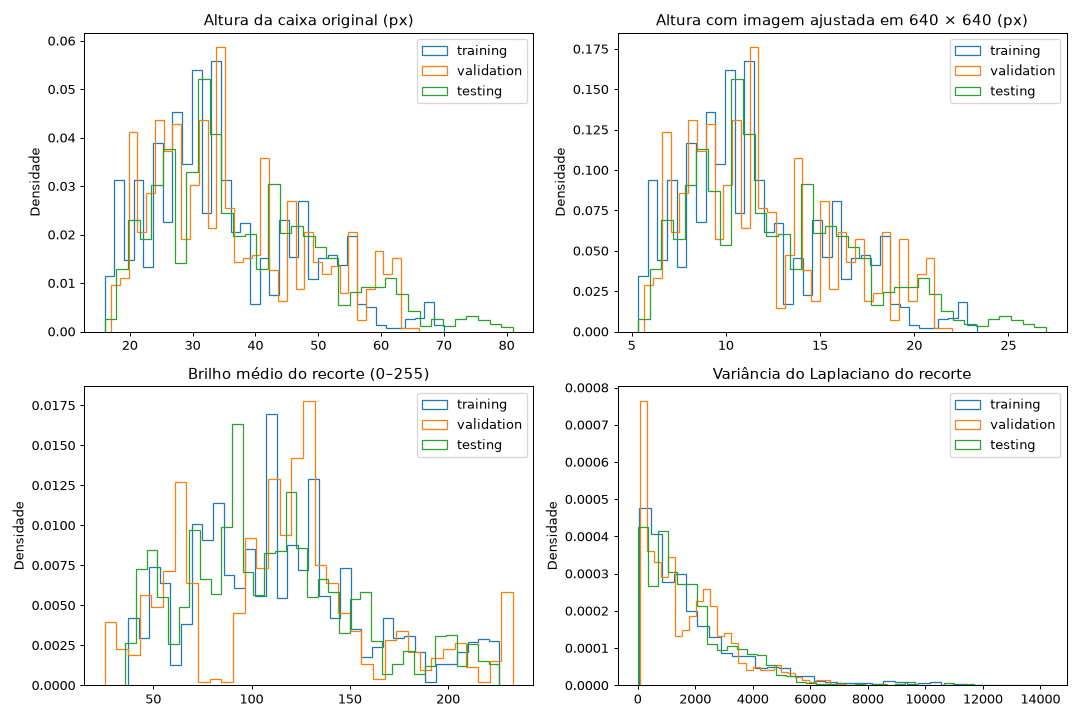

In [24]:
mostrar_json(resumo['metricas'])
for divisao in DIVISOES:
    subconjunto = [r for r in registros if r['divisao'] == divisao]
    print(divisao, 'altura da placa:', estatisticas(subconjunto, 'altura_placa'))
    medidas = [r['altura_em_640'] for r in subconjunto if 'altura_em_640' in r]
    print('Com altura < 10 px em 640:', sum((v < 10 for v in medidas)), 'de', len(medidas))
figura = graficos(registros)
exibir_figura(figura)


### 7. O contorno e o recorte correspondem à placa na imagem?

Amostragem reproduzível por tipo/layout/câmera, com semente 42, somente de treino e
validação. Verde mostra os cantos e laranja a caixa retangular. A coluna direita
mostra o recorte. A segunda galeria mostra extremos de tamanho, brilho e nitidez.
Isso permite inspeção humana; não é uma validação visual das 100% das anotações.


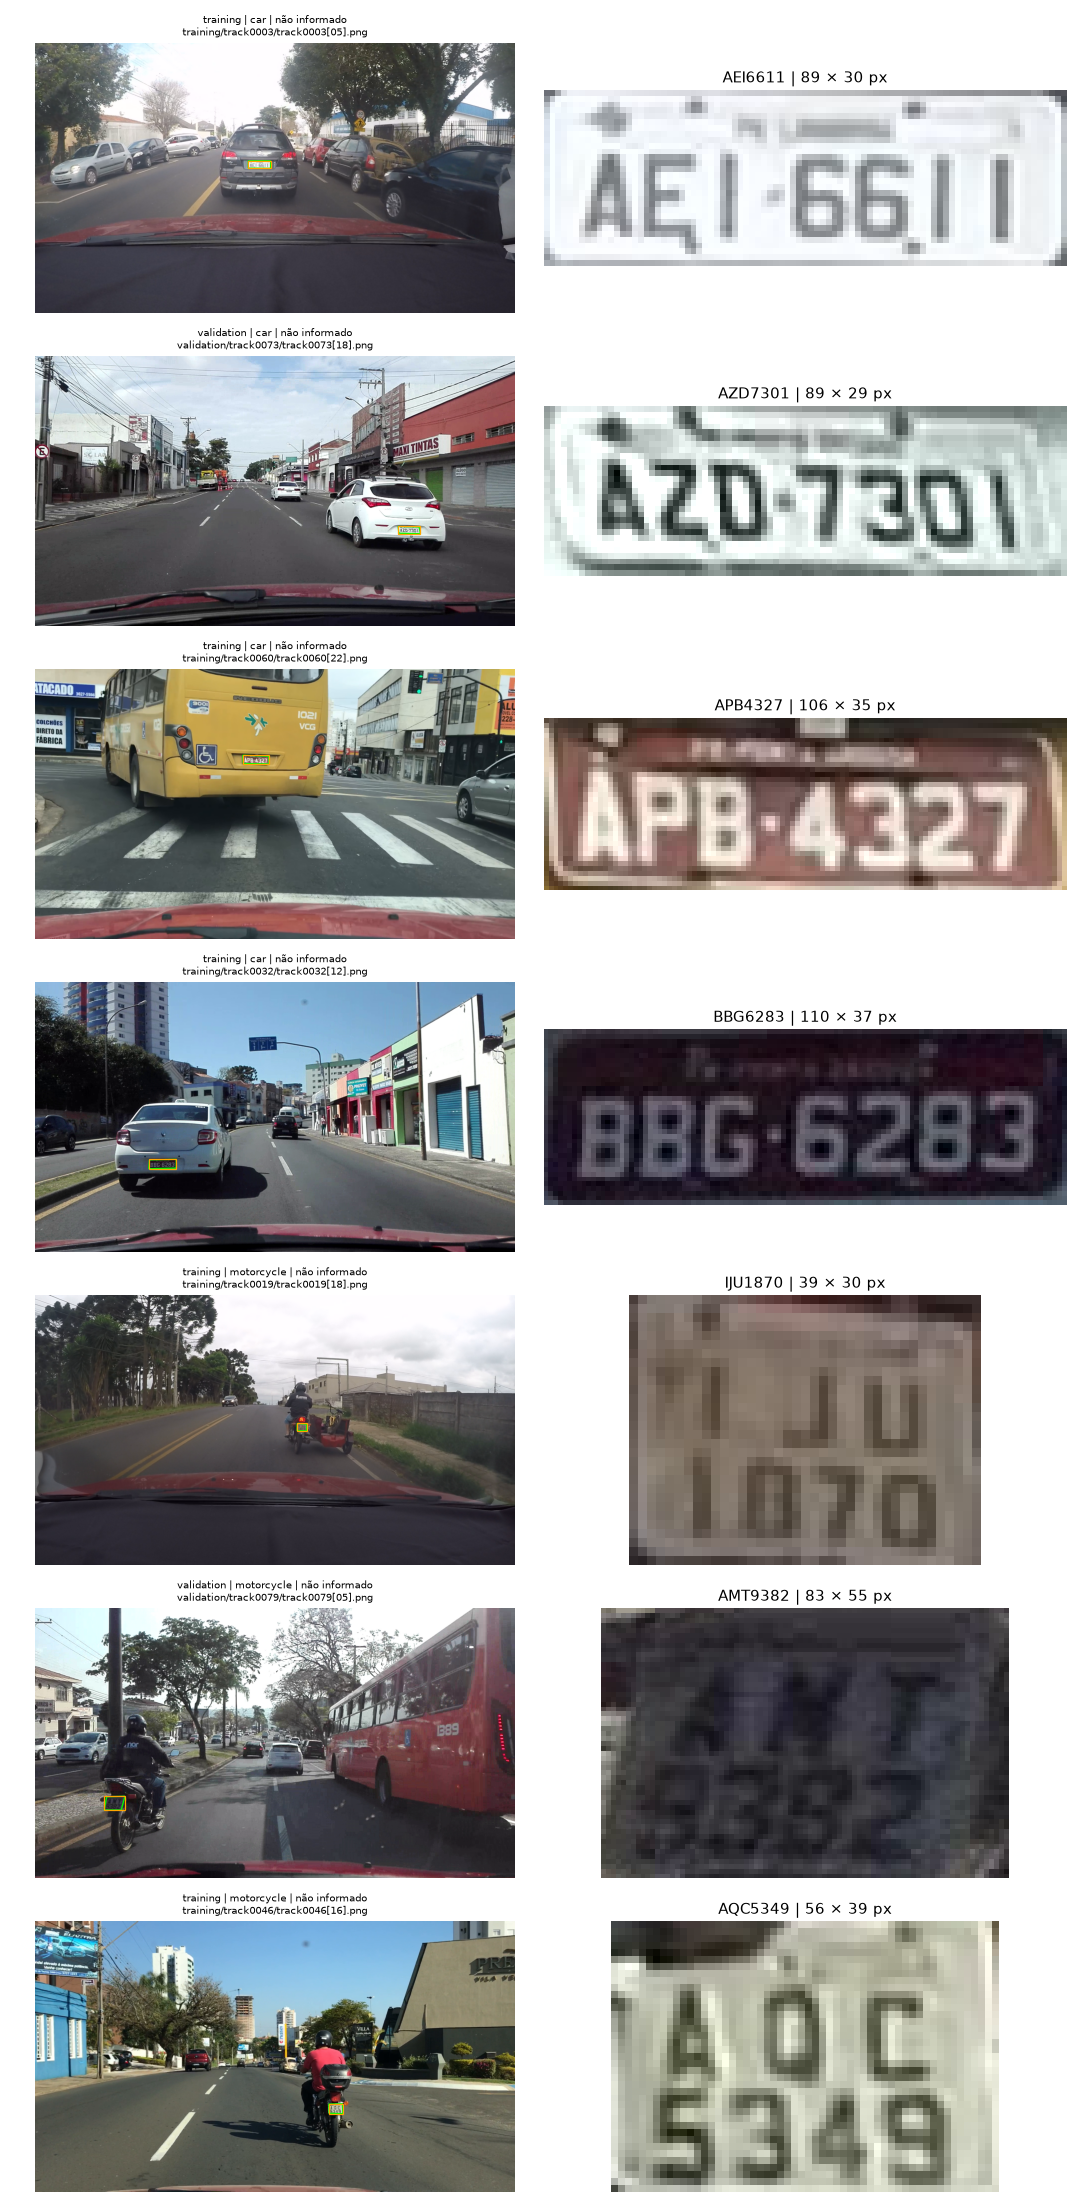

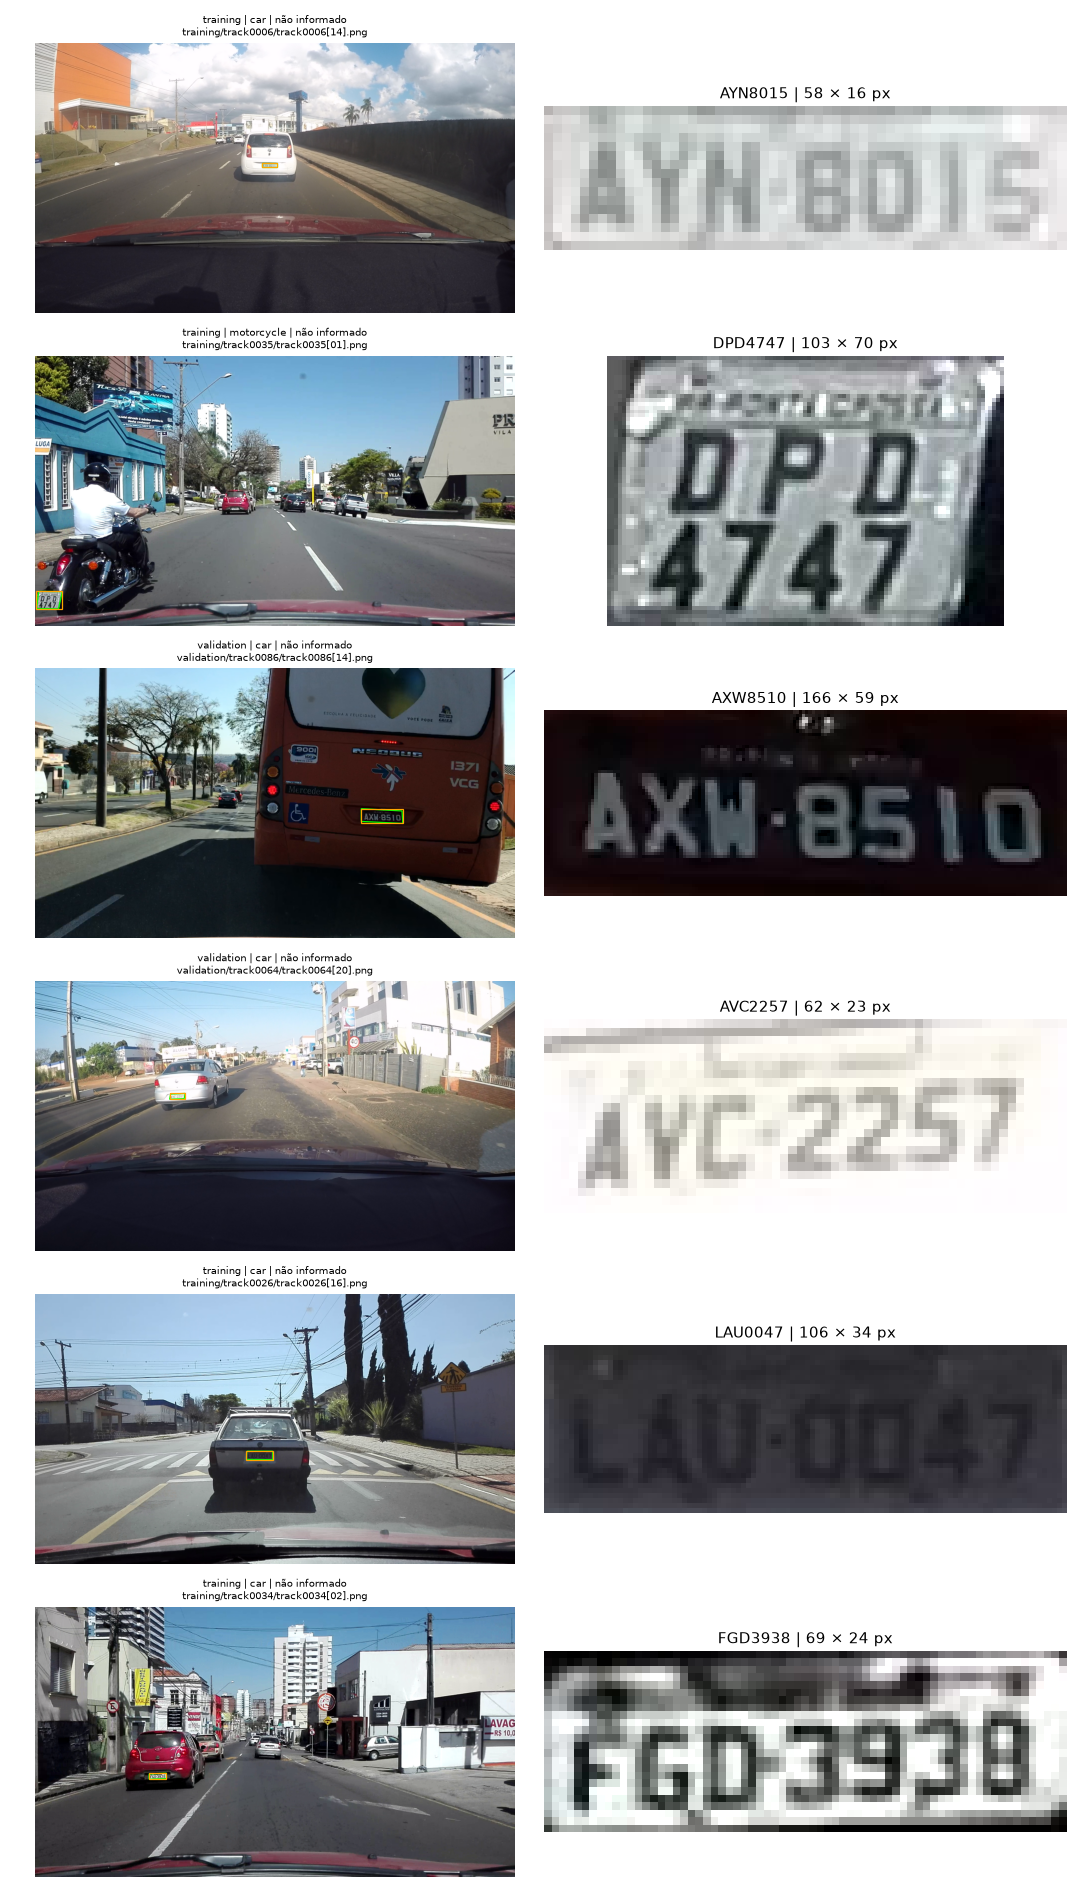

In [25]:
for extremos, nome_arquivo in [(False, 'amostras.png'), (True, 'extremos.png')]:
    figura = galeria(diretorio_raiz, nome_dataset, registros, extremos=extremos)
    if figura is not None:
        exibir_figura(figura)


### 8. Há placas compartilhadas ou imagens repetidas entre divisões?

Texto igual é um sinal de possível veículo repetido, mas pode haver erro de anotação.
Normalizamos apenas espaços externos e caixa das letras, preservando o original.
SHA-256 do arquivo detecta cópias byte a byte; SHA-256 dos pixels detecta imagens RGB
idênticas mesmo com metadados distintos. `dhash` igual é somente um candidato visual:
podem existir colisões e imagens semelhantes com hashes diferentes. Não fazemos uma
busca exaustiva de quase duplicatas por distância de Hamming nesta etapa.

Use `grupos_repetidos(registros, campo)` para consultar as listas completas em memória. No UFPR, tracks precisam permanecer
inteiros em qualquer protocolo futuro; textos repetidos podem ligar tracks distintos.


In [26]:
mostrar_json(resumo['sobreposicoes'])
mostrar_json(resumo['duplicatas'])


{
  "training x validation": {
    "quantidade": 0,
    "placas": [],
    "imagens_a": 0,
    "imagens_b": 0
  },
  "training x testing": {
    "quantidade": 2,
    "placas": [
      "AVA1466",
      "BBO8514"
    ],
    "imagens_a": 60,
    "imagens_b": 60
  },
  "validation x testing": {
    "quantidade": 0,
    "placas": [],
    "imagens_a": 0,
    "imagens_b": 0
  }
}
{
  "sha256_arquivo": {
    "grupos": 1,
    "imagens": 2,
    "grupos_entre_divisoes": 0
  },
  "sha256_pixels": {
    "grupos": 1,
    "imagens": 2,
    "grupos_entre_divisoes": 0
  },
  "dhash": {
    "grupos": 581,
    "imagens": 1430,
    "grupos_entre_divisoes": 0
  }
}


### 9. Quais caracteres aparecem nas placas?

Esta contagem descreve as anotações e ajuda a planejar a avaliação do OCR. Frequência
por imagem dá peso maior a veículos com várias capturas; não representa veículos
independentes. Caracteres raros e layouts distintos merecem métricas separadas.


In [27]:
mostrar_json(resumo['caracteres'])
print('Por posição:')
for posicao, contagem in enumerate(resumo['caracteres_por_posicao'], 1):
    print(posicao, contagem)
placas_unicas = {r['placa'] for r in registros if r.get('placa')}
print('Contagem por placa distinta:')
mostrar_json(dict(sorted(Counter(''.join(placas_unicas)).items())))


{
  "0": 1590,
  "1": 1800,
  "2": 1440,
  "3": 1710,
  "4": 1800,
  "5": 1680,
  "6": 1860,
  "7": 1770,
  "8": 2250,
  "9": 2100,
  "A": 3780,
  "B": 1200,
  "C": 330,
  "D": 270,
  "E": 300,
  "F": 180,
  "G": 240,
  "H": 180,
  "I": 420,
  "J": 300,
  "K": 240,
  "L": 300,
  "M": 540,
  "N": 180,
  "O": 360,
  "P": 510,
  "Q": 270,
  "R": 240,
  "S": 480,
  "T": 210,
  "U": 480,
  "V": 480,
  "W": 480,
  "X": 390,
  "Y": 600,
  "Z": 540
}
Por posição:
1 {'M': 240, 'A': 3180, 'I': 90, 'B': 690, 'P': 90, 'C': 30, 'L': 30, 'F': 60, 'D': 30, 'E': 30, 'G': 30}
2 {'L': 90, 'Q': 210, 'Z': 330, 'U': 180, 'V': 330, 'W': 240, 'Y': 390, 'S': 270, 'P': 240, 'M': 120, 'H': 90, 'C': 120, 'E': 120, 'B': 300, 'J': 90, 'R': 150, 'I': 90, 'O': 180, 'A': 450, 'T': 90, 'X': 330, 'K': 30, 'F': 30, 'G': 30}
3 {'S': 210, 'Y': 210, 'Z': 210, 'I': 240, 'X': 60, 'P': 180, 'E': 150, 'K': 210, 'R': 90, 'B': 210, 'L': 180, 'N': 180, 'O': 180, 'Q': 60, 'D': 240, 'C': 180, 'F': 90, 'J': 210, 'U': 300, 'A': 150, 

### 10. Como ficam as coordenadas YOLO e a conversão existente está consistente?

Para uma única classe placa, o formato é `0 centro_x centro_y largura altura`,
com as quatro medidas divididas pelas dimensões correspondentes da imagem.
Não arredondamos os pixels nem cortamos silenciosamente pontos fora dos limites.
Converter os cantos em caixa perde a orientação/perspectiva do quadrilátero.

Esta célula demonstra a representação e audita o derivado existente, sem criar
datasets nem alterar labels ou YAML. UFPR é comparado arquivo a arquivo; a pasta
RodoSol vazia é reportada como ainda não convertida.


In [28]:
exemplo = next((r for r in registros if r['apto_geometria_yolo']))
print(exemplo['caminho'])
print('0 ' + ' '.join((f'{v:.6f}' for v in exemplo['yolo'])))
auditoria_yolo = auditar_yolo(diretorio_raiz, nome_dataset, registros)
mostrar_json({**auditoria_yolo, 'problemas': auditoria_yolo['problemas'][:15]})
print('Total de problemas YOLO:', len(auditoria_yolo['problemas']))


testing/track0091/track0091[01].png
0 0.462240 0.476389 0.032813 0.019444
{
  "pasta": "C:\\Users\\igorm\\Documents\\programacao\\modelo-placa\\datasets_yolo\\UFPR",
  "problemas": [
    "dataset.yaml aponta para outra pasta; corrigir antes do treinamento",
    "Arquivo extra: labels\\training\\track0001.cache",
    "Arquivo extra: labels\\validation\\track0061.cache"
  ],
  "labels_verificadas": 4500,
  "imagens_verificadas": 4500,
  "yaml": {
    "path": "C:/Users/igorm/Documents/programacao/modelo-placa/dados_yolo",
    "train": "images/training",
    "val": "images/validation",
    "test": "images/testing",
    "names": {
      "0": "placa"
    }
  },
  "estado": "verificado com problemas"
}
Total de problemas YOLO: 3


### 11. Há sobreposição entre UFPR e RodoSol?

Esta célula lê a outra origem e compara os registros em memória, sem depender de arquivos intermediários. Pode demorar alguns minutos. Coincidência de texto não prova que as imagens sejam
duplicadas. Uma mistura de datasets exigiria preservar separações e investigar todos
os grupos que atravessam treino, validação e teste.


In [29]:
comparacao = comparar_datasets(diretorio_raiz, registros)


{'placa': 0, 'sha256_arquivo': 0, 'sha256_pixels': 0, 'dhash': 0}


### 12. O que esta análise permite decidir e quais limites permanecem?

- RodoSol fornece variedade de layouts e motos em câmeras fixas de pedágio; UFPR
  representa câmera e veículos em movimento. A adequação depende do cenário final.
- Opções para discutir: treinar por dataset e avaliar transferência; ou combinar apenas
  os treinos e reportar validação/teste separados por origem, tipo e layout.
- Preservar o protocolo oficial permite comparação, mas sobreposições encontradas
  devem ser declaradas. Um novo protocolo agrupado por veículo/placa exige decisão
  explícita, manifesto e semente; não basta dividir imagens aleatoriamente.
- Nenhum modelo foi treinado ou escolhido nesta auditoria. O treino anterior foi
  cancelado conforme informado por Igor. Testes anteriormente usados não recuperam
  o status de intocados ao apagar um treinamento.
- A auditoria não decide licença de uso, não estima desempenho e não revisa visualmente
  cada imagem. Não mede dia/noite como rótulo verdadeiro, nem garante ausência de
  quase duplicatas ou veículos repetidos com textos divergentes.
- Use treino/validação para escolhas de modelos e parâmetros. As estatísticas do teste
  aqui são diagnóstico de integridade, não resultados para otimização.

Os achados desta execução estão na seção seguinte.


### 12.1. Quais foram os achados desta execução?

- 4,500 imagens decodificadas; nenhum par ausente nesta execução.
- 148 textos de placa distintos; quantidade de imagens não equivale a veículos independentes.
- 0 erros estruturais e 0 avisos de texto nos critérios implementados.
- Mediana da altura da caixa: 34.0 px; na simulação de 640, 11.3 px.

- Há 61 imagens 1920 × 1088; as demais têm 1920 × 1080. Usar dimensões reais na normalização.
- Cinco anotações usam `Ccamera`. A análise preserva essa grafia e reporta o metadado ausente.
- Os 150 tracks têm 30 imagens cada. AVA1466 e BBO8514 aparecem no treino e no teste.
- `validation/track0090/track0090[14].png` e `[15].png` são idênticas em bytes e pixels.
- As 4.500 labels e imagens YOLO conferem com os brutos; o YAML ainda aponta para `dados_yolo`.
- A galeria confirma exemplos de placas pequenas e motos com duas linhas. Revisão visual é amostral.

Não foram encontrados textos de placa nem imagens exatas comuns aos dois datasets.
As listas completas podem ser consultadas em `registros` e `comparacao`.
Esses achados não comprovam ausência de todos os vazamentos nem qualidade visual de todas as anotações.
